In [1]:
#import required libraries
# Import numerical computations library
import numpy as np

# Import dataframe management library
import pandas as pd

# Import statistics library
import statsmodels.api as sm

# Import statistics library, allows R-like regression syntax
import statsmodels.formula.api as smf

# Import plotting library
import matplotlib.pyplot as plt

In [ ]:
#import data
pwt = pd.read_stata('data/pwt110.dta')
START_YEAR = int(pwt['year'].min())
END_YEAR = min(2023, int(pwt['year'].max()))
pwt = pwt.loc[pwt['year'].between(START_YEAR, END_YEAR)].copy()
print(f'PWT 11.0: {START_YEAR}–{END_YEAR}; GDP values in 2021 US dollars')
pwt.tail()

1950

In [10]:
#set indeces
countries = pwt['country']
countries = countries.drop_duplicates()

countrycodes = pwt['countrycode']
countrycodes = countrycodes.drop_duplicates()

# Set MultiIndex (Index becomes country&year couple)
pwt.set_index(['country', 'year'], inplace=True)
pwt.sort_index(inplace=True)
pwt.tail(5)

countrycode currency_unit         rgdpe         rgdpo  \
country  year                                                         
Zimbabwe 2019         ZWE     US Dollar  46541.140625  45106.468750   
         2020         ZWE     US Dollar  45985.085938  45983.898438   
         2021         ZWE     US Dollar  45625.347656  44440.199219   
         2022         ZWE     US Dollar  50148.527344  48054.238281   
         2023         ZWE     US Dollar  52258.898438  50540.847656   

                     pop       emp      avh        hc          ccon  \
country  year                                                         
Zimbabwe 2019  15.271368  5.272343  1903.71  2.713408  39602.753906   
         2020  15.526888  5.206007  1889.45  2.746586  41572.535156   
         2021  15.797210  5.298346  2011.57  2.770661  41325.707031   
         2022  16.069056  5.344455  2172.04  2.795292  46625.746094   
         2023  16.340822  5.504774  2311.02  2.820498  46345.812500   

                        cda  ...     csh_x     csh_m     csh_r      pl_c  \
country  year                ...                                           
Zimbabwe 2019  45432.328125  ...  0.189066 -0.242234  0.038880  0.501244   
         2020  47053.406250  ...  0.110438 -0.165574  0.029654  0.500685   
         2021  48130.085938  ...  0.172298 -0.279770  0.024442  0.616105   
         2022  54859.515625  ...  0.220504 -0.391468  0.021712  0.660731   
         2023  56080.398438  ...  0.179567 -0.308382  0.015704  0.736836   

                   pl_i      pl_g      pl_x      pl_m      pl_n      pl_k  
country  year                                                              
Zimbabwe 2019  0.534841  0.345942  0.505318  0.441230  0.339268  1.346716  
         2020  0.519637  0.290690  0.772591  0.680202  0.324105  1.353769  
         2021  0.549380  0.301370  0.558099  0.497615  0.347739  1.064607  
         2022  0.478931  0.280778  0.487665  0.432867  0.301817  1.006796  
         2023  0.507688  0.307323  0.505070  0.474047  0.308811  1.030187  

[5 rows x 49 columns]

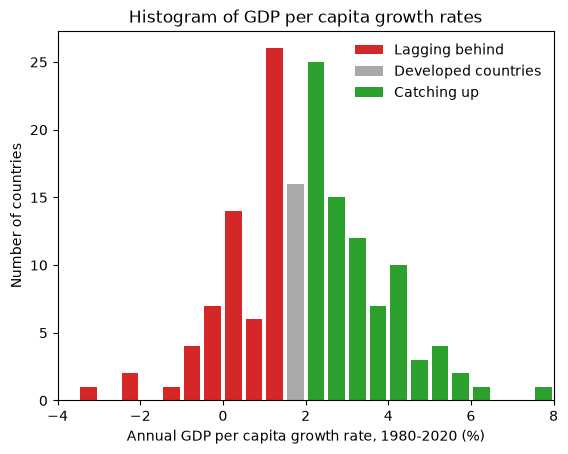

In [13]:
#HomeWork 1 Part A
#plotting the histogram of the average growth rate between 1980 and 2020 
hist_start_year=1980
hist_end_year=2020
x_80 = pwt.xs(hist_start_year, level='year')['rgdpe'] / pwt.xs(hist_start_year, level='year')['pop']
x_latest = pwt.xs(hist_end_year, level='year')['rgdpe'] / pwt.xs(hist_end_year, level='year')['pop']
g = 100 * ((x_latest / x_80) ** (1 / (hist_end_year - hist_start_year)) - 1)
g = g.replace([np.inf, -np.inf], np.nan).dropna()
low_edge = min(-10, np.floor(g.min() / .5) * .5)
high_edge = max(10, np.ceil(g.max() / .5) * .5)
plt.hist(g.dropna(), np.arange(-10, 2, 0.5), histtype='bar', rwidth=0.8, fc='C3', label='Lagging behind')
plt.hist(g.dropna(), np.arange(1.5, 2.5, 0.5), histtype='bar', rwidth=0.8, fc='darkgrey', label='Developed countries')
plt.hist(g.dropna(), np.arange(2, 10, 0.5), histtype='bar', rwidth=0.8, fc='C2', label='Catching up')
plt.xlim(-4, 8)
plt.title('Histogram of GDP per capita growth rates')
plt.xlabel(f'Annual GDP per capita growth rate, {hist_start_year}-{hist_end_year} (%)')
plt.ylabel('Number of countries')
plt.legend(frameon=False)
plt.show()


In [42]:
# Homework 2 Part B
first_year = 2000
second_year = 2022

gdp_per_capitas = pd.DataFrame({
    'x_2000': pwt.xs(first_year, level='year')['rgdpe'] / pwt.xs(first_year, level='year')['pop'],
    'x_2022': pwt.xs(second_year, level='year')['rgdpe'] / pwt.xs(second_year, level='year')['pop']
})

# Clean the dataset
gdp_per_capitas_clean = gdp_per_capitas.replace([np.inf, -np.inf], np.nan).dropna()

# Exclude nonpositive values
gdp_per_capitas_clean = gdp_per_capitas_clean[
    (gdp_per_capitas_clean['x_2000'] > 0) &
    (gdp_per_capitas_clean['x_2022'] > 0)
]
print(gdp_per_capitas.index.is_unique)
print(f"""Remaining countries: {len(gdp_per_capitas_clean)}
Excluded countries: {len(gdp_per_capitas) - len(gdp_per_capitas_clean)}""")
median_2000=round(gdp_per_capitas_clean['x_2000'].median(),2)
median_2022=round(gdp_per_capitas_clean['x_2022'].median())
p10_2000=round(gdp_per_capitas_clean['x_2000'].quantile(0.10))
p90_2000=round(gdp_per_capitas_clean['x_2000'].quantile(0.90))
p10_2022=round(gdp_per_capitas_clean['x_2022'].quantile(0.10))
p90_2022=round(gdp_per_capitas_clean['x_2022'].quantile(0.90))
print(f"""2000:
Median: {median_2000}
10th percentile: {p10_2000}
90th percentile: {p90_2000}

2022:
Median: {median_2022}
10th percentile: {p10_2022}
90th percentile: {p90_2022}""")


True
Remaining countries: 182
Excluded countries: 3
2000:
Median: 8758.92
10th percentile: 1391
90th percentile: 44307

2022:
Median: 18001
10th percentile: 2705
90th percentile: 63095


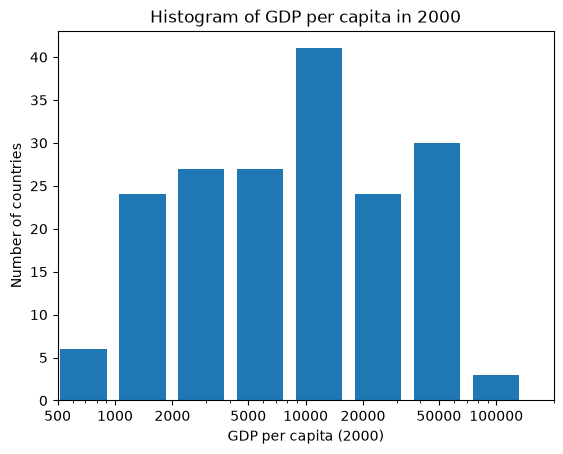

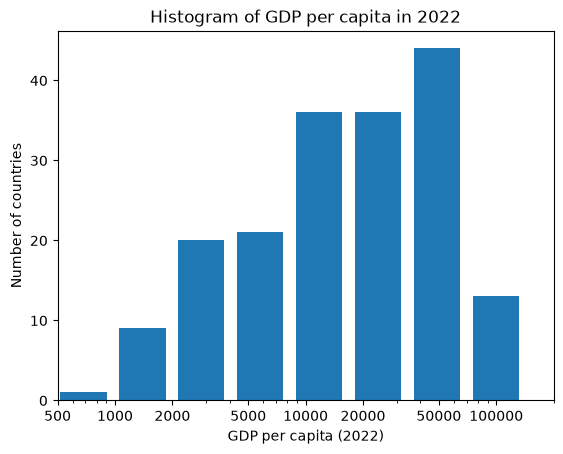

In [34]:
# continue HomeWork 1 B
# Log gdp per capita

log_bins = np.logspace(np.log(gdp_per_capitas_clean.min().min()),
                            np.log(gdp_per_capitas_clean.max().max()),
                            num=1+10, base=np.e)
def plotGdpPerCapita(gdp_per_capitas,year):

    plt.hist(gdp_per_capitas, bins=log_bins, histtype='bar', rwidth=0.8)

    plt.xscale('log')

    plt.xlim(500, 200000)

    plt.xticks([500, 1000, 2000, 5000, 10000, 20000, 50000, 100000], 
            [500, 1000, 2000, 5000, 10000, 20000, 50000, 100000])

    plt.title(f'Histogram of GDP per capita in {year}')
    plt.xlabel(f'GDP per capita ({year})')
    plt.ylabel('Number of countries')

    plt.show()
plotGdpPerCapita(gdp_per_capitas_clean['x_2000'],2000)
plotGdpPerCapita(gdp_per_capitas_clean['x_2022'],2022)


In [45]:
# continue HomeWork 1 B
# 90th percentile to 10th percentile
percentile_ratio_2000=round(p90_2000/p10_2000,2)
percentile_ratio_2022=round(p90_2022/p10_2022,2)
print(f"the ratio of the 90th percentile to the 10th percentile in 2000 is {percentile_ratio_2000}")
print(f"the ratio of the 90th percentile to the 10th percentile in 2022 is {percentile_ratio_2022}")

the ratio of the 90th percentile to the 10th percentile in 2000 is 31.85
the ratio of the 90th percentile to the 10th percentile in 2022 is 23.33


In [47]:
print(f"""
    Between 2000 and 2022, typical income across countries increased significantly, 
    with median GDP per capita rising from approximately {median_2000} to {median_2022}. At the same time, 
    income dispersion decreased, as the ratio of the 90th to the 10th percentile fell from 
    {percentile_ratio_2000} to {percentile_ratio_2022}. This suggests that although GDP per capita increased across the distribution,
    poorer countries experienced relatively stronger improvements than richer countries. 
    Each country receives equal weight in this comparison, regardless of its population size."""
)


    Between 2000 and 2022, typical income across countries increased significantly, 
    with median GDP per capita rising from approximately 8758.92 to 18001. At the same time, 
    income dispersion decreased, as the ratio of the 90th to the 10th percentile fell from 
    31.85 to 23.33. This suggests that although GDP per capita increased across the distribution,
    poorer countries experienced relatively stronger improvements than richer countries. 
    Each country receives equal weight in this comparison, regardless of its population size.


\begin{align}
k^{*} &= \left( \frac{s \bar{A}}{\delta+n} \right)^{1/(1-\alpha)}
\end{align}


In [61]:
#Task 3 a
A_basic=1;alpha_basic=1/3;delta_basic=0.4;n_basic=0.05;s_basic=0.5
def get_k_steady_state(svalue):
    return ((svalue*A_basic)/(delta_basic+n_basic))**(1/(1-alpha_basic))
k_steady_state=get_k_steady_state(s_basic)
print("Steady-state capital per worker:", round(k_steady_state, 4))


Steady-state capital per worker: 1.1712


\begin{align}
k_{t+1} = \frac{ s f \left( k_{t} \right) + \left( 1-\delta \right) k_{t} }{1+n}
\end{align}

\begin{align}
F \left( K, L \right) = \bar{A} K^{\alpha} L^{1-\alpha} \quad \to \quad f \left( k \right) = \bar{A} k^{\alpha}
\end{align}

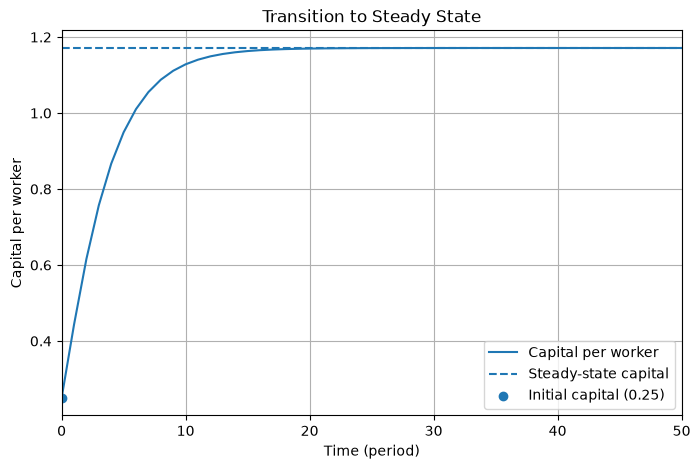

In [ ]:

# Production function in intensive form
def f_basic(k):
    return k**alpha_basic

# Function for k_{t+1}
def k_next_basic(k):
    return ( s_basic*A_basic*f_basic(k) + (1-delta_basic)*k ) / (1+n_basic)

k_ss_basic = ((s_basic*A_basic)/(delta_basic+n_basic))**(1/(1-alpha_basic))
# Calculate capital over time
periods = 50
capital_path = [0.25]

for t in range(periods):
    capital_path.append(k_next_basic(capital_path[-1]))

# Plot capital transition over time
plt.figure(figsize=(8, 5))

plt.plot(range(periods + 1), capital_path, label='Capital per worker')

plt.axhline(k_ss_basic, linestyle='--', label='Steady-state capital')
plt.scatter(0, 0.25, label='Initial capital (0.25)')

plt.xlabel('Time (period)')
plt.ylabel('Capital per worker')
plt.title('Transition to Steady State')
plt.xlim(0, 50)

plt.legend()
plt.grid(True)
plt.show()

new steady state capital per worker is 1.5396


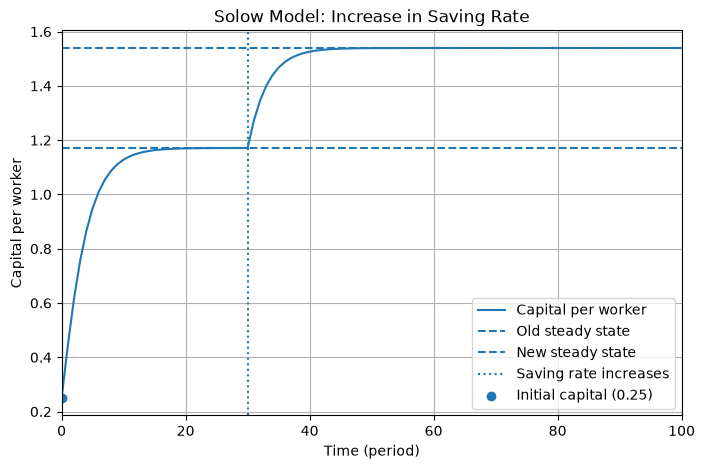

the steady-state capital increase from 1.1712 to 1.5396


In [ ]:
#Task 3 b
s_basic=0.6
k_new_steady_state=round(get_k_steady_state(s_basic),4)
print(f"new steady state capital per worker is {k_new_steady_state}")
# Periods 0 to 30: old saving rate
s_basic = 0.5
capital_path = [0.25]

for t in range(30):
    capital_path.append(k_next_basic(capital_path[-1]))

# Periods 30 to 100: new saving rate
s_basic = 0.6

for t in range(70):
    capital_path.append(k_next_basic(capital_path[-1]))

# Plot
plt.figure(figsize=(8, 5))

plt.plot(range(101), capital_path, label='Capital per worker')

plt.axhline(k_steady_state, linestyle='--', label='Old steady state')
plt.axhline(k_new_steady_state, linestyle='--', label='New steady state')

plt.axvline(30, linestyle=':', label='Saving rate increases')

plt.scatter(0, 0.25, label='Initial capital (0.25)')

plt.xlabel('Time (period)')
plt.ylabel('Capital per worker')
plt.title('Solow Model: Increase in Saving Rate')
plt.xlim(0, 100)

plt.legend()
plt.grid(True)
plt.show()

print(f"the steady-state capital increased from {round(k_steady_state,4)} to {k_new_steady_state}")
print(f"""When people become more prudent, they save a larger proportion of their income.
This increases investment, allowing the country to accumulate more capital per worker. Consequently, 
the steady-state level of capital per worker increases.""")

The new steady-state capital per worker is  1.1712


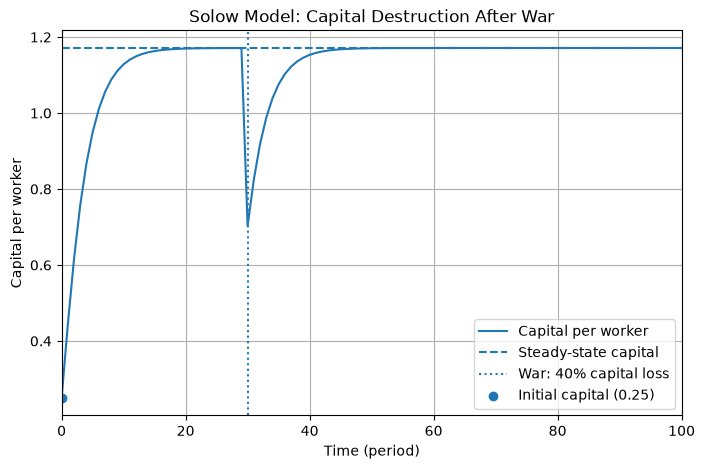

the steady-state capital per worker didnt change after war because all parameter controlling 
the capital per worker equation didnt change 


In [ ]:
#Task 3 c
s_basic = 0.5
k_ss_afterwar= ((s_basic*A_basic)/(delta_basic+n_basic))**(1/(1-alpha_basic))
print("The new steady-state capital per worker is ",round(k_ss_afterwar,4))
capital_path = [0.25]

for t in range(30):
    capital_path.append(k_next_basic(capital_path[-1]))

capital_path[-1] *= 0.6
for t in range(70):
    capital_path.append(k_next_basic(capital_path[-1]))

# Plot
plt.figure(figsize=(8, 5))

plt.plot(range(101), capital_path, label='Capital per worker')

plt.axhline(k_ss_afterwar, linestyle='--', label='Steady-state capital')

plt.axvline(30, linestyle=':', label='War: 40% capital loss')

plt.scatter(0, 0.25, label='Initial capital (0.25)')

plt.xlabel('Time (period)')
plt.ylabel('Capital per worker')
plt.title('Solow Model: Capital Destruction After War')
plt.xlim(0, 100)

plt.legend()
plt.grid(True)
plt.show()

print(f"""The steady-state capital per worker did not change after the war because all the 
parameters determining the steady-state level remained unchanged. The war only destroyed 40%
 of the existing capital stock. Therefore, capital per worker gradually recovers and converges
   back to its original steady-state level.""")

In [85]:
mrw =pd.read_stata('data/MRW1992.dta')
mrw_countries = mrw['country']
mrw.head()

,country,N,I,O,Y60,Y85,Y_growth,pop_growth,invest,school
0,Algeria,1,1,0,2485.0,4371.0,4.8,2.6,24.100000,4.5
1,Angola,1,0,0,1588.0,1171.0,0.8,2.1,5.800000,1.8
2,Benin,1,0,0,1116.0,1071.0,2.2,2.4,10.800000,1.8
3,Botswana,1,1,0,959.0,3671.0,8.6,3.2,28.299999,2.9
4,Burkina Faso,1,0,0,529.0,857.0,2.9,0.9,12.700000,0.4


In [87]:
# Match country names explicitly. Report unavailable countries.
country_aliases = {
    'CentralAfr. Rep.': 'Central African Republic', 'Congo, Peop. Rep.': 'Congo',
    'Ivory Cost': "Côte d'Ivoire", 'S. Africa': 'South Africa',
    'Tanzania': 'U.R. of Tanzania: Mainland', 'Zaire': 'D.R. of the Congo',
    'Burma': 'Myanmar', 'Hong Kong': 'China, Hong Kong SAR',
    'Korea, Rep. of': 'Republic of Korea', 'Syrian Arab Rep.': 'Syrian Arab Republic',
    'Germany, Fed. Rep.': 'Germany', 'Dominican Rep.': 'Dominican Republic',
    'Trinidad & Tobago': 'Trinidad and Tobago', 'Bolivia': 'Bolivia (Plurinational State of)',
    'Venezuela': 'Venezuela (Bolivarian Republic of)'}
# PWT 11.0 uses a revised name for Turkey; use its stable country code.
country_aliases['Turkey'] = pwt.loc[pwt['countrycode'].eq('TUR')].index.get_level_values('country')[0]
available = set(pwt.index.get_level_values('country'))
matched, not_found = [], []
for country in mrw.loc[mrw['N'].eq(1), 'country']:
    candidate = country_aliases.get(country, country)
    if candidate in available:
        matched.append(candidate)
    else:
        not_found.append(country)
print('Countries unavailable in PWT:', not_found)


Countries unavailable in PWT: ['Papua New Guinea']


In [88]:
# Preserve order while removing duplicate matched names.
mrw_pwt_countries = list(dict.fromkeys(matched))


In [89]:
assert len(mrw_pwt_countries) == len(set(mrw_pwt_countries))


In [90]:
# Construct the replication dataset using the explicit 1985–END_YEAR window.
rows = []
for country in mrw_pwt_countries:
    period = pwt.loc[country].sort_index().loc[1985:END_YEAR]
    first, last = period.loc[1985], period.loc[END_YEAR]
    investment = period['csh_i'].mean()
    growth_term = .05 + period['emp'].pct_change(fill_method=None).mean()
    human_index = period['hc'].mean()
    def positive_log(value):
        return np.log(value) if pd.notna(value) and np.isfinite(value) and value > 0 else np.nan
    def output_per_worker(row):
        return row['rgdpo'] / row['emp'] if pd.notna(row['emp']) and row['emp'] > 0 else np.nan
    rows.append({'country': country, 'y_23': positive_log(output_per_worker(last)),
                 'y_85': positive_log(output_per_worker(first)),
                 's': positive_log(investment), 'δ_n_g': positive_log(growth_term),
                 's_h': positive_log(10 * positive_log(human_index))})
mrw_rep_raw = pd.DataFrame(rows).set_index('country').replace([np.inf, -np.inf], np.nan)
mrw_rep_raw['y_23_85'] = mrw_rep_raw['y_23'] - mrw_rep_raw['y_85']
excluded = mrw_rep_raw.index[mrw_rep_raw.isna().any(axis=1)].tolist()
print('Excluded because required values are missing or invalid:', excluded)
mrw_rep = mrw_rep_raw.dropna().copy()
print(f'Replication window: 1985–{END_YEAR}; complete countries: {len(mrw_rep)}')
mrw_rep.head()


Excluded because required values are missing or invalid: ['Chad', 'Somalia']
Replication window: 1985–2023; complete countries: 95


,y_23,y_85,s,δ_n_g,s_h,y_23_85
country,,,,,,
Algeria,10.963898,11.359983,-1.164556,-2.536208,1.887979,-0.396086
Angola,9.484999,8.929098,-1.144811,-2.484416,1.035082,0.555901
Benin,9.323925,8.738811,-1.994986,-2.546255,1.433951,0.585114
Botswana,10.632174,9.761808,-1.376208,-2.492512,2.213175,0.870365
Burkina Faso,8.889307,7.940952,-1.885522,-2.643378,0.244581,0.948355


\begin{align}
\log y_{t}^{*} = \log A_{0} + t \cdot \log \left( 1+g \right) - \frac{\alpha+\beta}{1-\alpha-\beta} \log \left( \delta+n+g \right)
+ \frac{\alpha}{1-\alpha-\beta} \log s_{k} + \frac{\beta}{1-\alpha-\beta} \log s_{h}
\end{align}


In [91]:
#Task 4
# Run regression on the mrw_rep data
mrw_rep_h_results = smf.ols('y_23 ~ s + δ_n_g + s_h', data=mrw_rep).fit()
print(mrw_rep_h_results.summary())

                            OLS Regression Results                            
Dep. Variable:                   y_23   R-squared:                       0.660
Model:                            OLS   Adj. R-squared:                  0.649
Method:                 Least Squares   F-statistic:                     58.95
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           2.91e-21
Time:                        02:29:21   Log-Likelihood:                -101.90
No. Observations:                  95   AIC:                             211.8
Df Residuals:                      91   BIC:                             222.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.1497      1.705      2.434      0.0

The unrestricted regression results show that all three explanatory variables have the theoretically expected coefficient signs. The investment share (s) and human capital (s_h) have positive coefficients, while the depreciation, population growth, and technology growth term (δ_n_g) has a negative coefficient.

All three explanatory variables are statistically significant at the 5% level. The model has an R-squared of 0.660 and an adjusted R-squared of 0.649, indicating that it explains approximately 66% of the cross-country variation in output per worker. Furthermore, the overall F-test is statistically significant (p-value < 0.001), suggesting that the explanatory variables are jointly significant.

Overall, the unrestricted human capital augmented Solow model provides a reasonably strong explanation of differences in output per worker across countries.


### Human Capital Augmented Solow Model – Transformed Equation

The original steady-state equation is:

\[
\begin{aligned}
\log y_t^* =\;& \log A_0+t\log(1+g)\\
&-\frac{\alpha+\beta}{1-\alpha-\beta}\log(\delta+n+g)\\
&+\frac{\alpha}{1-\alpha-\beta}\log s_k\\
&+\frac{\beta}{1-\alpha-\beta}\log s_h
\end{aligned}
\]

Splitting and combining the terms gives:

\[
\boxed{
\begin{aligned}
\log y_t^* =\;& \log A_0+t\log(1+g)\\
&+\frac{\alpha}{1-\alpha-\beta}
\log\left(\frac{s_k}{\delta+n+g}\right)\\
&+\frac{\beta}{1-\alpha-\beta}
\log\left(\frac{s_h}{\delta+n+g}\right)
\end{aligned}
}
\]

In [96]:
mrw_rep['restricted'] = mrw_rep['s'] - mrw_rep['δ_n_g']
mrw_rep['restricted_h'] = mrw_rep['s_h'] - mrw_rep['δ_n_g']


print(r'\t Restricted regression')
mrw_h_results_restricted = smf.ols('y_23 ~ restricted + restricted_h', data=mrw_rep).fit()
print(mrw_h_results_restricted.summary())
# α+β
α_β = ((mrw_h_results_restricted.params['restricted']+mrw_h_results_restricted.params['restricted_h'])/
       (1+mrw_h_results_restricted.params['restricted']+mrw_h_results_restricted.params['restricted_h']))

print('')
print('Implied α =', mrw_h_results_restricted.params['restricted'] * (1-α_β))
print('Implied β =', mrw_h_results_restricted.params['restricted_h'] * (1-α_β))
print('')
print('Test of restriction p-value =', mrw_rep_h_results.compare_f_test(mrw_h_results_restricted)[1])

\t Restricted regression
                            OLS Regression Results                            
Dep. Variable:                   y_23   R-squared:                       0.660
Model:                            OLS   Adj. R-squared:                  0.653
Method:                 Least Squares   F-statistic:                     89.40
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           2.71e-22
Time:                        03:10:49   Log-Likelihood:                -101.90
No. Observations:                  95   AIC:                             209.8
Df Residuals:                      92   BIC:                             217.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        4.0684

The restricted regression produces an implied physical capital share (α) of 0.3135 and a human capital share (β) of 0.3655. Both values are positive and economically reasonable, indicating that physical and human capital contribute positively to output per worker. Their combined share is approximately 0.6790.

The restricted model has an R-squared of 0.660, explaining approximately 66% of the cross-country variation in output per worker. Compared with the unrestricted model, its R-squared remains unchanged, while its adjusted R-squared increases from 0.649 to 0.653.

The F-test of the restrictions produces a p-value of 0.9594, which is greater than the 5% significance level. Therefore, we fail to reject the null hypothesis that the restrictions are valid. This suggests that imposing the theoretical restrictions does not significantly reduce the explanatory power of the model.
